<a href="https://colab.research.google.com/github/SlastuninAE/python-practice-algos/blob/master/636-01/hw-7-slastunin-a-e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install umap-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE, Isomap, LocallyLinearEmbedding
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import umap

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

In [3]:
breast_cancer = load_breast_cancer()
X_train = breast_cancer.data
y_train = breast_cancer.target

In [4]:
rf = RandomForestClassifier(max_depth=5,  n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
print(f"Random Forest (max_depth={5}): train={train_acc:.3f}")

Random Forest (max_depth=5): train=0.991


In [5]:
X_train_scaled = StandardScaler().fit_transform(X_train)
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

In [9]:
rf = RandomForestClassifier(max_depth=5, n_estimators=100, random_state=42)
rf.fit(X_pca, y_train)

train_acc_pca = accuracy_score(y_train, rf.predict(X_pca))
print(f"Random Forest (max_depth={5}): train={train_acc_pca:.3f}")

Random Forest (max_depth=5): train=0.982


In [10]:
print(f"Accuracy упало на {100 - train_acc_pca/train_acc*100}%")

Accuracy упало на 0.8865248226950371%


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


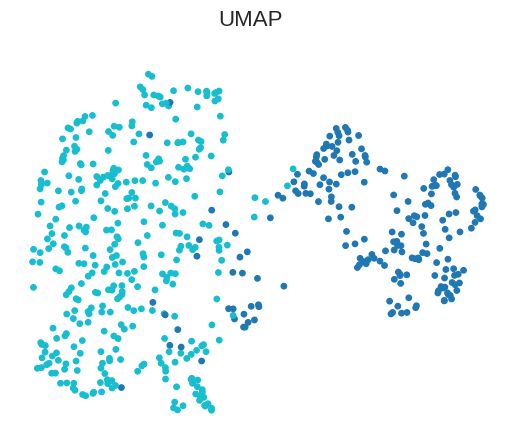

In [8]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_train_scaled)
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_train, cmap='tab10', s=15)
plt.axis('off')

plt.suptitle('UMAP', fontsize=16)
plt.show()